# Import Libraries

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import Perceptron
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix,accuracy_score
%matplotlib inline

## Get the Data
Read in the Social_Network_Ads.csv file and set it to a data frame called ad_data.

In [21]:
df = pd.read_csv('/Users/patriciasiuhaliu/Documents/Semester 2/python/week 9/Lab 8/Social_Network_Ads.csv')
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


## Preprocessing
Preprocess the data as necessary. Split the data into training and test datasets.

In [35]:
X=df[['Gender', 'Age','EstimatedSalary']]
#X=np.array(X)
#print(X)
##ct = ColumnTransformer(transformers=[('encoder',OneHotEncoder(),[0])],remainder='passthrough')
#X=np.array(ct.fit_transform(X))
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
# Encode labels in column 'Country'. 
X['Gender']= label_encoder.fit_transform(X['Gender']) 
print(X)
y=df['Purchased']
y=np.asarray(y)
print(X.shape,y.shape)
print(y)
from sklearn.model_selection import train_test_split
print(X.shape,y.shape)
print(y)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=101)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)


     Gender  Age  EstimatedSalary
0         1   19            19000
1         1   35            20000
2         0   26            43000
3         0   27            57000
4         1   19            76000
..      ...  ...              ...
395       0   46            41000
396       1   51            23000
397       0   50            20000
398       1   36            33000
399       0   49            36000

[400 rows x 3 columns]
(400, 3) (400,)
[0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0 1 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0
 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0
 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0 1 0 1 0 1 1 0 0 0 1 0 0 0 1 0 1
 1 1 0 0 1 1 0 1 1 0 1 1 0 1 0 0 0 1 1 0 1 1 0 1 0 1 0 1 0 0 1 1 0 1 0 0 1
 1 0 1 1 0 1 1 0 0 1 0 0 1 

/var/folders/t8/4cz6934j38v_m257qfz846ym0000gn/T/ipykernel_6814/1538912220.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X['Gender']= label_encoder.fit_transform(X['Gender'])


# Modelling

Perform a comparative study between the Perceptron model and Logistic regression classification models for predicting the Purchased variable.

## Perceptron Model

In [36]:
clf = Perceptron(tol=1e-3, random_state=0)
clf.fit(np.array(X_train), np.array(y_train))
y_pred_percep = clf.predict(np.array(X_test))
print(X_train)
print(X_test)
print(np.array(y_test))
print(y_train)
print(y_pred)
print(clf.score(X_test, y_test))
confusion_mat_percep = confusion_matrix(y_test, y_pred_percep)
print(confusion_mat_percep)
print(classification_report(y_test, y_pred_percep))
print(accuracy_score(y_test, y_pred_percep))

     Gender  Age  EstimatedSalary
17        1   45            26000
138       0   28            59000
57        1   28            79000
234       0   38           112000
287       0   48           138000
..      ...  ...              ...
63        1   32           120000
326       1   41            72000
337       1   35            79000
11        0   26            52000
351       1   37            75000

[320 rows x 3 columns]
     Gender  Age  EstimatedSalary
38        0   26            72000
387       1   39            71000
270       0   43           133000
181       0   31            71000
195       1   34            43000
..      ...  ...              ...
130       1   31            58000
13        1   32            18000
141       0   18            68000
304       0   40            60000
167       0   35            71000

[80 rows x 3 columns]
[0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 1 0 0 1 1 1 0 0 0 0 0 1 0 1 0 0 0 0 1 1 1
 1 1 0 0 0 0 0 1 0 0 0 1 0 0 1 0 1 1 0 1 0 0 1 1 1 0 0 0 1 0 1

/Users/patriciasiuhaliu/opt/anaconda3/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1248: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/Users/patriciasiuhaliu/opt/anaconda3/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1248: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/Users/patriciasiuhaliu/opt/anaconda3/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1248: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start,

## Logistic Regression




In [37]:
clf = LogisticRegression(random_state=0).fit(X_train, y_train)
clf.predict(X_test)
clf.predict_proba(X_test)
y_pred = clf.predict(X_test)
print(y_test,y_pred)
print(clf.score(X_test, y_test))
confusion_mat = confusion_matrix(y_test, y_pred)
print(confusion_mat)
print(classification_report(y_test, y_pred))
print(accuracy_score(y_test, y_pred))

[0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 1 0 0 1 1 1 0 0 0 0 0 1 0 1 0 0 0 0 1 1 1
 1 1 0 0 0 0 0 1 0 0 0 1 0 0 1 0 1 1 0 1 0 0 1 1 1 0 0 0 1 0 1 0 0 0 0 1 1
 0 0 0 0 0 0] [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0]
0.675
[[54  0]
 [26  0]]
              precision    recall  f1-score   support

           0       0.68      1.00      0.81        54
           1       0.00      0.00      0.00        26

    accuracy                           0.68        80
   macro avg       0.34      0.50      0.40        80
weighted avg       0.46      0.68      0.54        80

0.675


/Users/patriciasiuhaliu/opt/anaconda3/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1248: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/Users/patriciasiuhaliu/opt/anaconda3/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1248: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/Users/patriciasiuhaliu/opt/anaconda3/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1248: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start,

## Predictions and Evaluations


In [26]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.68      1.00      0.81        54
           1       0.00      0.00      0.00        26

    accuracy                           0.68        80
   macro avg       0.34      0.50      0.40        80
weighted avg       0.46      0.68      0.54        80



/Users/patriciasiuhaliu/opt/anaconda3/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1248: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/Users/patriciasiuhaliu/opt/anaconda3/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1248: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/Users/patriciasiuhaliu/opt/anaconda3/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1248: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start,

## Visualization

Use plotting method of your choice to compare the above two models.

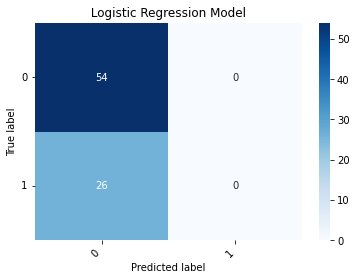

In [33]:
plt.figure()

heatmap = sns.heatmap(confusion_mat, annot=True, cmap="Blues")

heatmap.yaxis.set_ticklabels(heatmap.yaxis.get_ticklabels(), rotation=0, ha='right')

heatmap.xaxis.set_ticklabels(heatmap.xaxis.get_ticklabels(), rotation=45, ha='right')

plt.ylabel('True label')

plt.xlabel('Predicted label')

plt.title(' Logistic Regression Model ')

plt.show() 

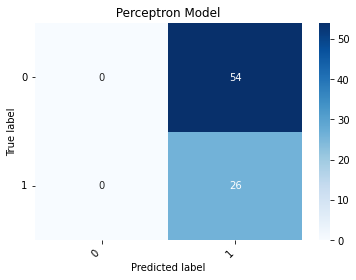

In [34]:
plt.figure()

heatmap = sns.heatmap(confusion_mat_percep, annot=True, cmap="Blues")

heatmap.yaxis.set_ticklabels(heatmap.yaxis.get_ticklabels(), rotation=0, ha='right')

heatmap.xaxis.set_ticklabels(heatmap.xaxis.get_ticklabels(), rotation=45, ha='right')

plt.ylabel('True label')

plt.xlabel('Predicted label')

plt.title(' Perceptron Model ')

plt.show() 